<a href="https://colab.research.google.com/github/plnmrnk/market-activity-anomaly-detector/blob/main/market_activity_anomaly_monitor_v0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Market Activity Anomaly Monitor - V0

## 1 - Project Overview

**Objective**: identify unusual price movements and trading volumes in European equity markets using Python-based statistical analysis.

**Market Data**: Historical daily stock prices and trading volumes for three Euronext Paris-listed companies: LVMH, BNP Paribas and Airbus.

**Methodology**: Detect statistical anomalies using historical rolling averages, standard deviations and trading volume ratios.

**Tools**: Python, pandas, yfinance, Matplotlib and Seaborn.

**Scope**: Exploratory financial data analysis. Detected anomalies do not necessarily indicate market manipulation or suspicious trading activity.

In [1]:
!pip install yfinance

In [2]:
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

## 2 - Data Collection

In [3]:
stocks = yf.download(['MC.PA', 'AIR.PA', 'BNP.PA'],
                     start='2025-06-01',
                     end='2026-10-02',
                     auto_adjust=True)

# MC.PA = LVMH, AIR.PA = AirBus, BNP.PA = BNP Paribas

stocks.head()

[*********************100%***********************]  3 of 3 completed


Price            Close                               High             \
Ticker          AIR.PA     BNP.PA       MC.PA      AIR.PA     BNP.PA   
Date                                                                   
2025-06-02  159.630371  69.718567  465.525391  160.042749  70.163906   
2025-06-03  163.420334  70.182083  462.013428  163.420334  70.254794   
2025-06-04  167.092484  69.654945  464.988831  170.646817  71.299978   
2025-06-05  162.497391  70.436569  458.599091  166.817557  70.581990   
2025-06-06  162.340286  71.018234  459.720917  162.870498  71.281804   

Price                          Low                               Open  \
Ticker           MC.PA      AIR.PA     BNP.PA       MC.PA      AIR.PA   
Date                                                                    
2025-06-02  467.183783  156.979359  69.091452  455.916363  159.001983   
2025-06-03  466.061892  158.295037  68.955125  454.599355  160.749681   
2025-06-04  467.573993  165.796440  69.318665  459.379503  166.837206   
2025-06-05  472.110259  162.497391  69.636776  456.257812  166.424820   
2025-06-06  462.549963  160.828233  70.336590  456.257779  162.006458   

Price                               Volume                   
Ticker         BNP.PA       MC.PA   AIR.PA   BNP.PA   MC.PA  
Date                                                         
2025-06-02  69.800368  460.306272   707780  2724245  432937  
2025-06-03  69.827629  464.159587  1192092  2766585  594655  
2025-06-04  70.291144  463.379203  1551623  3045846  529986  
2025-06-05  69.818545  469.378742  1228318  2986549  545281  
2025-06-06  70.681954  456.550428   869676  2413794  289488

## 3 - Data Quality Assessment

The dataset contains 256 daily trading observations and 5 market variables, covering October 1, 2025 to October 1, 2026.
No missing values were identified in the dataset.
The data is suitable for the initial exploratory analysis.

In [4]:
stocks.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 343 entries, 2025-06-02 to 2026-10-01
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   (Close, AIR.PA)   343 non-null    float64
 1   (Close, BNP.PA)   343 non-null    float64
 2   (Close, MC.PA)    343 non-null    float64
 3   (High, AIR.PA)    343 non-null    float64
 4   (High, BNP.PA)    343 non-null    float64
 5   (High, MC.PA)     343 non-null    float64
 6   (Low, AIR.PA)     343 non-null    float64
 7   (Low, BNP.PA)     343 non-null    float64
 8   (Low, MC.PA)      343 non-null    float64
 9   (Open, AIR.PA)    343 non-null    float64
 10  (Open, BNP.PA)    343 non-null    float64
 11  (Open, MC.PA)     343 non-null    float64
 12  (Volume, AIR.PA)  343 non-null    int64  
 13  (Volume, BNP.PA)  343 non-null    int64  
 14  (Volume, MC.PA)   343 non-null    int64  
dtypes: float64(12), int64(3)
memory usage: 42.9 KB


In [5]:
stocks.describe()

Price        Close                                High              \
Ticker      AIR.PA      BNP.PA       MC.PA      AIR.PA      BNP.PA   
count   343.000000  343.000000  343.000000  343.000000  343.000000   
mean    187.042881   81.913252  502.759084  189.118106   82.704357   
std      15.098242   12.721526   62.581327   15.006100   12.793751   
min     156.292053   61.412880  379.500000  158.157591   62.033215   
25%     174.646210   70.934044  459.975006  176.935351   71.463580   
50%     189.459198   80.605583  482.450012  191.089077   81.291704   
75%     198.752472   90.287586  531.152710  200.593461   91.199061   
max     216.204987  109.163841  641.637329  217.285040  110.150957   

Price                      Low                                Open  \
Ticker       MC.PA      AIR.PA      BNP.PA       MC.PA      AIR.PA   
count   343.000000  343.000000  343.000000  343.000000  343.000000   
mean    509.237720  185.046127   81.029304  496.986586  187.082370   
std      62.506535   15.196202   12.599538   61.804753   15.114233   
min     389.250000  154.563989   61.206109  379.100006  155.369113   
25%     465.988742  172.476531   70.126178  454.599681  174.825311   
50%     488.100006  187.377648   79.045353  475.963587  189.498467   
75%     540.585170  196.953018   89.573405  526.604263  198.835794   
max     643.802043  214.250000  108.815445  633.273720  216.008622   

Price                                 Volume                              
Ticker      BNP.PA       MC.PA        AIR.PA        BNP.PA         MC.PA  
count   343.000000  343.000000  3.430000e+02  3.430000e+02  3.430000e+02  
mean     81.951758  502.985704  1.087332e+06  2.382863e+06  5.112056e+05  
std      12.722650   62.117777  4.826757e+05  1.200394e+06  2.419701e+05  
min      61.422280  387.000000  1.082580e+05  3.080920e+05  5.587800e+04  
25%      71.031873  460.824997  7.891935e+05  1.678220e+06  3.721960e+05  
50%      80.333018  482.531760  9.769910e+05  2.130568e+06  4.743410e+05  
75%      90.292428  534.734898  1.258500e+06  2.729240e+06  5.747230e+05  
max     109.202545  642.818093  3.877479e+06  1.307298e+07  2.474373e+06

## 4 - Data Preparation

In [6]:
stocks_clean = stocks.loc[ :, ['Close', 'Volume']]

stocks_clean.head()

Price            Close                          Volume                 
Ticker          AIR.PA     BNP.PA       MC.PA   AIR.PA   BNP.PA   MC.PA
Date                                                                   
2025-06-02  159.630371  69.718567  465.525391   707780  2724245  432937
2025-06-03  163.420334  70.182083  462.013428  1192092  2766585  594655
2025-06-04  167.092484  69.654945  464.988831  1551623  3045846  529986
2025-06-05  162.497391  70.436569  458.599091  1228318  2986549  545281
2025-06-06  162.340286  71.018234  459.720917   869676  2413794  289488

In [7]:
stocks_clean = (stocks_clean.stack(level = 'Ticker', future_stack = True)).swaplevel('Date', 'Ticker').sort_index()


In [8]:
stocks_clean.info()

<class 'pandas.core.frame.DataFrame'>
MultiIndex: 1029 entries, ('AIR.PA', Timestamp('2025-06-02 00:00:00')) to ('MC.PA', Timestamp('2026-10-01 00:00:00'))
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   1029 non-null   float64
 1   Volume  1029 non-null   int64  
dtypes: float64(1), int64(1)
memory usage: 21.9+ KB


## 5 - Daily Returns Analysis

In [9]:
stocks_clean['Daily Return'] = stocks_clean.groupby('Ticker')['Close'].pct_change(fill_method=None) * 100
#The Daily Return data sould be read in percentage (ex: 3.606890%, -2,296135%, etc.)

stocks_clean

Price                   Close   Volume  Daily Return
Ticker Date                                         
AIR.PA 2025-06-02  159.630371   707780           NaN
       2025-06-03  163.420334  1192092      2.374212
       2025-06-04  167.092484  1551623      2.247058
       2025-06-05  162.497391  1228318     -2.750030
       2025-06-06  162.340286   869676     -0.096681
...                       ...      ...           ...
MC.PA  2026-09-25  396.850006   508148     -0.062956
       2026-09-28  398.799988   499958      0.491365
       2026-09-29  394.600006   372219     -1.053155
       2026-09-30  390.000000   829329     -1.165739
       2026-10-01  379.500000   773338     -2.692308

[1029 rows x 3 columns]

In [10]:
stocks_clean.groupby('Ticker')['Daily Return'].agg(['mean', 'std', 'min', 'max'])

,mean,std,min,max
Ticker,,,,
AIR.PA,0.059189,1.743771,-6.753046,7.772731
BNP.PA,0.094300,1.713445,-7.731334,7.477308
MC.PA,-0.042267,1.879412,-7.890714,12.218466


## 6 -Unusual Trading Activity Detection

### 6.1 Price Anomaly Detection

In [11]:
mean_return = (stocks_clean.groupby('Ticker')['Daily Return']
               .transform(lambda x: x.shift(1).rolling(60).mean())
               )
std_return = (stocks_clean.groupby('Ticker')['Daily Return']
              .transform(lambda x: x.shift(1).rolling(60).std())
              )
upper_threshold = mean_return + (std_return * 2)
lower_threshold = mean_return - (std_return * 2)

In [12]:
price_anomalies = (stocks_clean
                   .loc[(stocks_clean['Daily Return'] < lower_threshold) | (stocks_clean['Daily Return'] > upper_threshold), :]
                   )

price_anomalies

Price                   Close    Volume  Daily Return
Ticker Date                                          
AIR.PA 2025-12-01  189.086090   3877479     -5.805821
       2025-12-03  194.525574   2159616      3.999999
       2026-01-19  206.582779   1088437     -3.219871
       2026-02-19  183.705521   3076080     -6.753046
       2026-03-19  160.985336   1962764     -3.722842
       2026-03-23  163.381058   2108959      3.405413
       2026-04-01  164.853851   2248144      4.402430
       2026-04-08  172.080322   2385184      7.772731
       2026-04-17  176.223755   1859573      4.482478
       2026-04-29  174.619995   2334773      5.129433
       2026-05-06  188.500000   2670945      5.982233
       2026-07-22  208.300003   2342279      7.040080
BNP.PA 2025-08-26   70.009399   7613260     -4.227286
       2025-10-06   70.962242   3901585     -3.205123
       2025-10-17   70.388901   3930791     -3.962554
       2025-10-20   64.946899  13072979     -7.731334
       2025-11-20   65.811592   5282670      4.398373
       2026-01-09   81.959030   7020926      5.696962
       2026-02-13   84.026810   3943675     -2.391088
       2026-03-02   86.545731   3460803     -3.581159
       2026-03-03   83.002319   4597542     -4.094265
       2026-03-10   83.058723   3027246      3.562645
       2026-03-12   80.643181   3478616     -4.069768
       2026-04-01   80.248421   2811388      5.420427
       2026-04-08   84.571953   5316923      7.477308
       2026-05-06   87.795799   3070460      5.215146
       2026-06-12   93.573151   3251218      5.166409
       2026-07-08   95.102211   2559855     -3.448620
       2026-08-27   97.415176   3464946     -4.786228
       2026-09-18   97.492592   5485737     -2.929278
       2026-10-01   91.540001   3969937     -3.642104
MC.PA  2025-09-04  486.889587    595875     -4.166664
       2025-10-15  583.272461   1376612     12.218466
       2026-01-16  599.425720    574531     -2.637041
       2026-01-19  573.449280    568048     -4.333555
       2026-01-21  575.810791    401160      2.666676
       2026-01-28  534.091064   1402549     -7.890714
       2026-02-20  545.800110    929807      4.365003
       2026-03-02  512.148865    774130     -4.337431
       2026-03-13  466.099731    845874     -4.303030
       2026-04-08  490.846222    948639      6.854456
       2026-05-06  474.000000    755072      5.111429
       2026-05-11  452.000000    683161     -4.379101
       2026-07-23  453.549988    858456     -4.314349
       2026-09-09  411.250000   1029072     -3.586916

In [13]:
upper_threshold.notna().groupby('Ticker').sum()

,Daily Return
Ticker,
AIR.PA,282
BNP.PA,282
MC.PA,282


In [14]:
price_anomalies.groupby('Ticker').size()

,0
Ticker,
AIR.PA,12
BNP.PA,19
MC.PA,14


In [15]:
price_anomalies_frequency = ((price_anomalies.groupby('Ticker').size()) / (upper_threshold.notna().groupby('Ticker').sum())) * 100

price_anomalies_frequency

,0
Ticker,
AIR.PA,4.255319
BNP.PA,6.737589
MC.PA,4.964539


In [16]:
alerts = (price_anomalies.shape[0] / upper_threshold.notna().sum()) * 100

alerts

np.float64(5.319148936170213)

### 6.2 Volume Anomaly Detection

In [17]:
stocks_clean['Average Volume 20D'] = (stocks_clean.groupby('Ticker')['Volume'].transform(lambda x: x.shift(1).rolling(20).mean()))

stocks_clean.loc['BNP.PA']

Price,Close,Volume,Daily Return,Average Volume 20D
Date,,,,
2025-06-02,69.718567,2724245,NaN,NaN
2025-06-03,70.182083,2766585,0.664839,NaN
2025-06-04,69.654945,3045846,-0.751100,NaN
2025-06-05,70.436569,2986549,1.122137,NaN
2025-06-06,71.018234,2413794,0.825800,NaN
...,...,...,...,...
2026-09-25,99.300003,1845774,0.883880,2086258.75
2026-09-28,98.260002,2138699,-1.047332,2067151.65
2026-09-29,97.400002,1677350,-0.875230,2001670.50


In [18]:
stocks_clean['Volume Ratio'] = (stocks_clean['Volume'] / stocks_clean['Average Volume 20D'])

stocks_clean

Price                   Close   Volume  Daily Return  Average Volume 20D  \
Ticker Date                                                                
AIR.PA 2025-06-02  159.630371   707780           NaN                 NaN   
       2025-06-03  163.420334  1192092      2.374212                 NaN   
       2025-06-04  167.092484  1551623      2.247058                 NaN   
       2025-06-05  162.497391  1228318     -2.750030                 NaN   
       2025-06-06  162.340286   869676     -0.096681                 NaN   
...                       ...      ...           ...                 ...   
MC.PA  2026-09-25  396.850006   508148     -0.062956           621027.85   
       2026-09-28  398.799988   499958      0.491365           623070.45   
       2026-09-29  394.600006   372219     -1.053155           620705.70   
       2026-09-30  390.000000   829329     -1.165739           618431.55   
       2026-10-01  379.500000   773338     -2.692308           633601.45   

Price              Volume Ratio  
Ticker Date                      
AIR.PA 2025-06-02           NaN  
       2025-06-03           NaN  
       2025-06-04           NaN  
       2025-06-05           NaN  
       2025-06-06           NaN  
...                         ...  
MC.PA  2026-09-25      0.818237  
       2026-09-28      0.802410  
       2026-09-29      0.599671  
       2026-09-30      1.341020  
       2026-10-01      1.220543  

[1029 rows x 5 columns]

In [19]:
stocks_clean.groupby('Ticker')['Volume Ratio'].agg('mean')

,Volume Ratio
Ticker,
AIR.PA,1.011251
BNP.PA,1.012081
MC.PA,1.022219


In [20]:
volume_anomalies = stocks_clean.loc[(stocks_clean['Volume Ratio'] > 2), :]

volume_anomalies

Price                   Close    Volume  Daily Return  Average Volume 20D  \
Ticker Date                                                                 
AIR.PA 2025-12-01  189.086090   3877479     -5.805821           815393.20   
       2025-12-02  187.043823   2063938     -1.080072           976171.75   
       2025-12-03  194.525574   2159616      3.999999          1048304.15   
       2026-01-27  195.782349   2107630     -1.482213           937769.90   
       2026-02-19  183.705521   3076080     -6.753046          1136846.75   
       2026-03-20  158.000488   3167914     -1.854112          1421749.55   
       2026-05-29  179.699997   3476455      1.125492          1367477.10   
       2026-07-22  208.300003   2342279      7.040080          1015705.25   
       2026-09-18  193.380005   2621206     -1.084396           844766.75   
BNP.PA 2025-08-26   70.009399   7613260     -4.227286          2024585.10   
       2025-10-20   64.946899  13072979     -7.731334          2286745.30   
       2025-10-21   63.847218   8255408     -1.693201          2860156.70   
       2025-12-19   75.755714   6202498      0.448655          2858479.35   
       2026-01-09   81.959030   7020926      5.696962          2316886.40   
       2026-03-20   77.193756   7305963     -2.793227          2720394.45   
       2026-05-29   89.953705   4405488      1.296855          2039334.85   
       2026-06-19   98.305519   5148719      0.474782          2027671.10   
       2026-08-27   97.415176   3464946     -4.786228          1458541.00   
       2026-08-31   99.466835   3448322      0.214514          1547952.40   
       2026-09-18   97.492592   5485737     -2.929278          1837853.30   
MC.PA  2025-08-26  474.353973   2474373     -0.368806           418485.10   
       2025-10-15  583.272461   1376612     12.218466           522424.75   
       2026-01-20  560.854614    775476     -2.196300           332455.15   
       2026-01-28  534.091064   1402549     -7.890714           377924.55   
       2026-03-20  450.602448   1359678     -0.499720           604318.25   
       2026-05-29  473.049988   1701998     -1.642587           533655.10   
       2026-06-19  499.250000   1653923     -1.158188           650960.10   
       2026-07-23  453.549988    858456     -4.314349           418120.30   
       2026-09-09  411.250000   1029072     -3.586916           456288.90   
       2026-09-18  402.799988   1227232     -2.304148           525240.20   

Price              Volume Ratio  
Ticker Date                      
AIR.PA 2025-12-01      4.755349  
       2025-12-02      2.114319  
       2025-12-03      2.060104  
       2026-01-27      2.247492  
       2026-02-19      2.705800  
       2026-03-20      2.228180  
       2026-05-29      2.542240  
       2026-07-22      2.306062  
       2026-09-18      3.102875  
BNP.PA 2025-08-26      3.760405  
       2025-10-20      5.716850  
       2025-10-21      2.886348  
       2025-12-19      2.169859  
       2026-01-09      3.030328  
       2026-03-20      2.685626  
       2026-05-29      2.160257  
       2026-06-19      2.539228  
       2026-08-27      2.375625  
       2026-08-31      2.227667  
       2026-09-18      2.984861  
MC.PA  2025-08-26      5.912691  
       2025-10-15      2.635044  
       2026-01-20      2.332573  
       2026-01-28      3.711188  
       2026-03-20      2.249937  
       2026-05-29      3.189322  
       2026-06-19      2.540744  
       2026-07-23      2.053132  
       2026-09-09      2.255308  
       2026-09-18      2.336516

### 6.3 Combined Anomaly Detection

In [21]:
anomalies_dates = price_anomalies.index.intersection(volume_anomalies.index)

anomalies = stocks_clean.loc[anomalies_dates, :]

anomalies

Price                   Close    Volume  Daily Return  Average Volume 20D  \
Ticker Date                                                                 
AIR.PA 2025-12-01  189.086090   3877479     -5.805821           815393.20   
       2025-12-03  194.525574   2159616      3.999999          1048304.15   
       2026-02-19  183.705521   3076080     -6.753046          1136846.75   
       2026-07-22  208.300003   2342279      7.040080          1015705.25   
BNP.PA 2025-08-26   70.009399   7613260     -4.227286          2024585.10   
       2025-10-20   64.946899  13072979     -7.731334          2286745.30   
       2026-01-09   81.959030   7020926      5.696962          2316886.40   
       2026-08-27   97.415176   3464946     -4.786228          1458541.00   
       2026-09-18   97.492592   5485737     -2.929278          1837853.30   
MC.PA  2025-10-15  583.272461   1376612     12.218466           522424.75   
       2026-01-28  534.091064   1402549     -7.890714           377924.55   
       2026-07-23  453.549988    858456     -4.314349           418120.30   
       2026-09-09  411.250000   1029072     -3.586916           456288.90   

Price              Volume Ratio  
Ticker Date                      
AIR.PA 2025-12-01      4.755349  
       2025-12-03      2.060104  
       2026-02-19      2.705800  
       2026-07-22      2.306062  
BNP.PA 2025-08-26      3.760405  
       2025-10-20      5.716850  
       2026-01-09      3.030328  
       2026-08-27      2.375625  
       2026-09-18      2.984861  
MC.PA  2025-10-15      2.635044  
       2026-01-28      3.711188  
       2026-07-23      2.053132  
       2026-09-09      2.255308

In [22]:
anomalies_frequency = ((upper_threshold.notna()) & (stocks_clean['Average Volume 20D'].notna())).sum()

anomalies_frequency

np.int64(846)

In [23]:
stocks_analysis = stocks_clean.loc[(stocks_clean['Average Volume 20D'].notna()) & (upper_threshold.notna())]

stocks_analysis.shape

(846, 5)

In [24]:
price_anomalies.groupby('Ticker').size()

,0
Ticker,
AIR.PA,12
BNP.PA,19
MC.PA,14


In [25]:
volume_anomalies.groupby('Ticker').size()

,0
Ticker,
AIR.PA,9
BNP.PA,11
MC.PA,10


In [26]:
anomalies.groupby('Ticker').size()

,0
Ticker,
AIR.PA,4
BNP.PA,5
MC.PA,4


In [27]:
combined_alert_rate = (anomalies.shape[0] / anomalies_frequency) * 100

combined_alert_rate

np.float64(1.5366430260047281)

### 6.4 Validation and Sanity Checks

In [28]:
bnpp_test = stocks_clean.loc[('BNP.PA'), :]

bnpp_test = bnpp_test.assign(Mean_Return = mean_return.loc[('BNP.PA'), :],
                 Standard_Deviation = std_return.loc[('BNP.PA'), :],
                 Upper = upper_threshold.loc[('BNP.PA'), :],
                 Lower = lower_threshold.loc[('BNP.PA'), :])

bnpp_test

Price,Close,Volume,Daily Return,Average Volume 20D,Volume Ratio,Mean_Return,Standard_Deviation,Upper,Lower
Date,,,,,,,,,
2025-06-02,69.718567,2724245,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-06-03,70.182083,2766585,0.664839,NaN,NaN,NaN,NaN,NaN,NaN
2025-06-04,69.654945,3045846,-0.751100,NaN,NaN,NaN,NaN,NaN,NaN
2025-06-05,70.436569,2986549,1.122137,NaN,NaN,NaN,NaN,NaN,NaN
2025-06-06,71.018234,2413794,0.825800,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
2026-09-25,99.300003,1845774,0.883880,2086258.75,0.884729,0.000333,1.441681,2.883695,-2.883030
2026-09-28,98.260002,2138699,-1.047332,2067151.65,1.034612,0.009200,1.445511,2.900222,-2.881822
2026-09-29,97.400002,1677350,-0.875230,2001670.50,0.837975,-0.023189,1.447075,2.870961,-2.917339


In [29]:
bnpp_test['Mean_Return'].first_valid_index()

Timestamp('2025-08-26 00:00:00')

In [30]:
bnpp_test.iloc[60:62, :]

Price,Close,Volume,Daily Return,Average Volume 20D,Volume Ratio,Mean_Return,Standard_Deviation,Upper,Lower
Date,,,,,,,,,
2025-08-25,73.099525,2581332,-3.538003,2015962.3,1.280447,NaN,NaN,NaN,NaN
2025-08-26,70.009399,7613260,-4.227286,2024585.1,3.760405,0.091374,1.586449,3.264272,-3.081524


## 7 - Results Summary

In [31]:
results_summary = pd.concat([price_anomalies.groupby('Ticker').size().rename('Price Alerts'),
                            volume_anomalies.groupby('Ticker').size().rename('Volume Alerts'),
                            anomalies.groupby('Ticker').size().rename('Combined Alerts')],axis=1)
results_summary.loc['Total', :] = results_summary.sum()
results_summary = results_summary.fillna(0).astype(int)

results_summary

,Price Alerts,Volume Alerts,Combined Alerts
Ticker,,,
AIR.PA,12,9,4
BNP.PA,19,11,5
MC.PA,14,10,4
Total,45,30,13


In [32]:
print(f'Price Alert Rate: {alerts:.2f}%')

Price Alert Rate: 5.32%


In [33]:
print(f'Combined Alert Rate: {combined_alert_rate:.2f}%')

Combined Alert Rate: 1.54%


###Key Findings

Across three equities, the model identified 36 price anomalies and 25 volume anomalies, including 8 trading sessions where both conditions were satisfied.

BNP Paribas recorded the highest number of price anomalies (14), while Airbus recorded the highest number of volume anomalies (9).

Combined alerts represented approximately 1.37% of eligible stock-date observations, illustrating the selectivity of requiring both unusual returns and elevated trading volumes.

These findings describe statistical deviations from historical trading patterns and should not be interpreted as evidence of market manipulation

## 8 - Market Anomalies Visualization

In [34]:
def plot_market_anomalies(ticker):
  stocks_data = stocks_clean.loc[ticker]
  if ticker in anomalies.index.get_level_values('Ticker'):
     stocks_alerts = anomalies.loc[ticker]
  else:
     stocks_alerts = stocks_data.iloc[0:0]
  fig, axes = plt.subplots(2, 1, figsize =(12,10))

  sns.lineplot(
      data=stocks_data,
      x=stocks_data.index,
      y='Close',
      color='navy',
      label='Closing Price',
      ax=axes[0])
  sns.scatterplot(
      data=stocks_alerts,
      x=stocks_alerts.index,
      y='Close',
      color='red',
      label='Price & Volume Anomalies',
      s=100,
      ax=axes[0])
  axes[1].bar(
      stocks_data.index,
      stocks_data['Volume'],
      width=3,
      label='Daily Trading Volume')
  sns.lineplot(
      data=stocks_data,
      x=stocks_data.index,
      y='Average Volume 20D',
      color='navy',
      label='20-D Average Volume',
      ax=axes[1])
  sns.scatterplot(
      data=stocks_alerts,
      x=stocks_alerts.index,
      y='Volume',
      color='red',
      s=100,
      label='Price & Volume Anomalies',
      ax=axes[1])

  axes[0].set(
      title=f'{ticker} | Price Activity',
      xlabel='Date',
      ylabel='Closing Price (€)'
  )

  axes[1].set(
      title=f'{ticker} | Trading Volume Activity',
      xlabel='Date',
      ylabel='Trading Volume (Shares)'
  )

  axes[0].legend()
  axes[1].legend()
  plt.tight_layout()

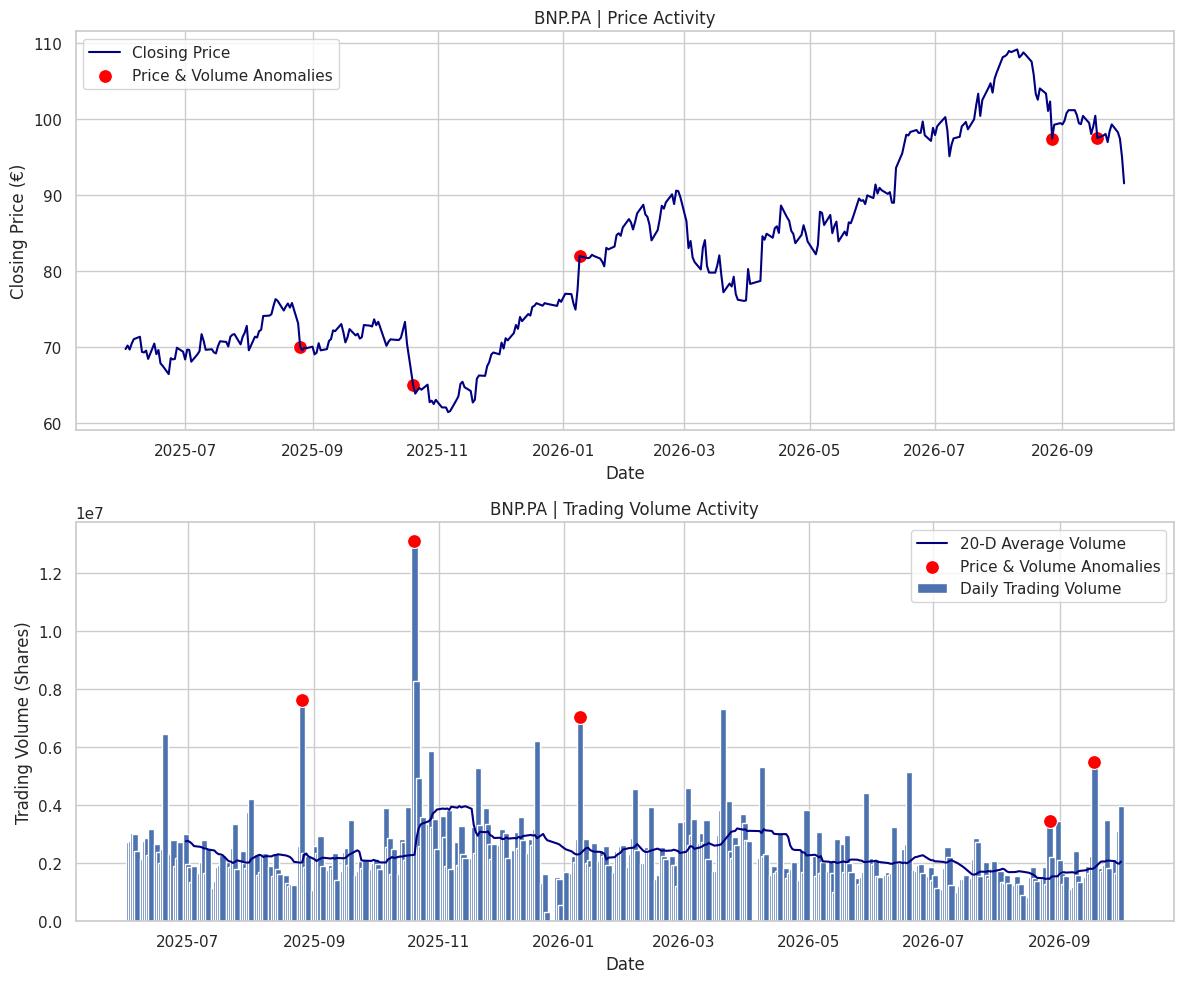

In [35]:
plot_market_anomalies('BNP.PA')

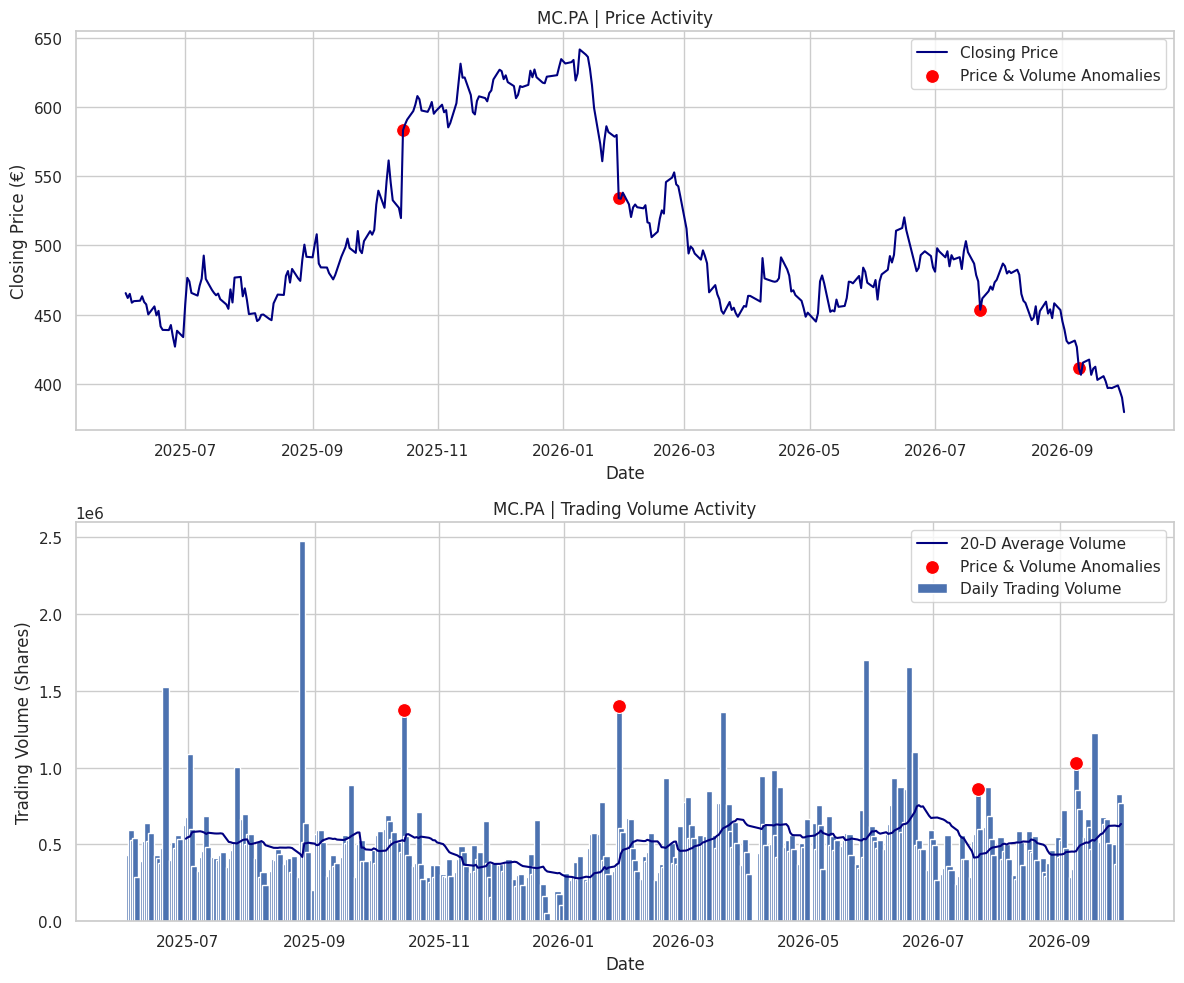

In [36]:
plot_market_anomalies('MC.PA')

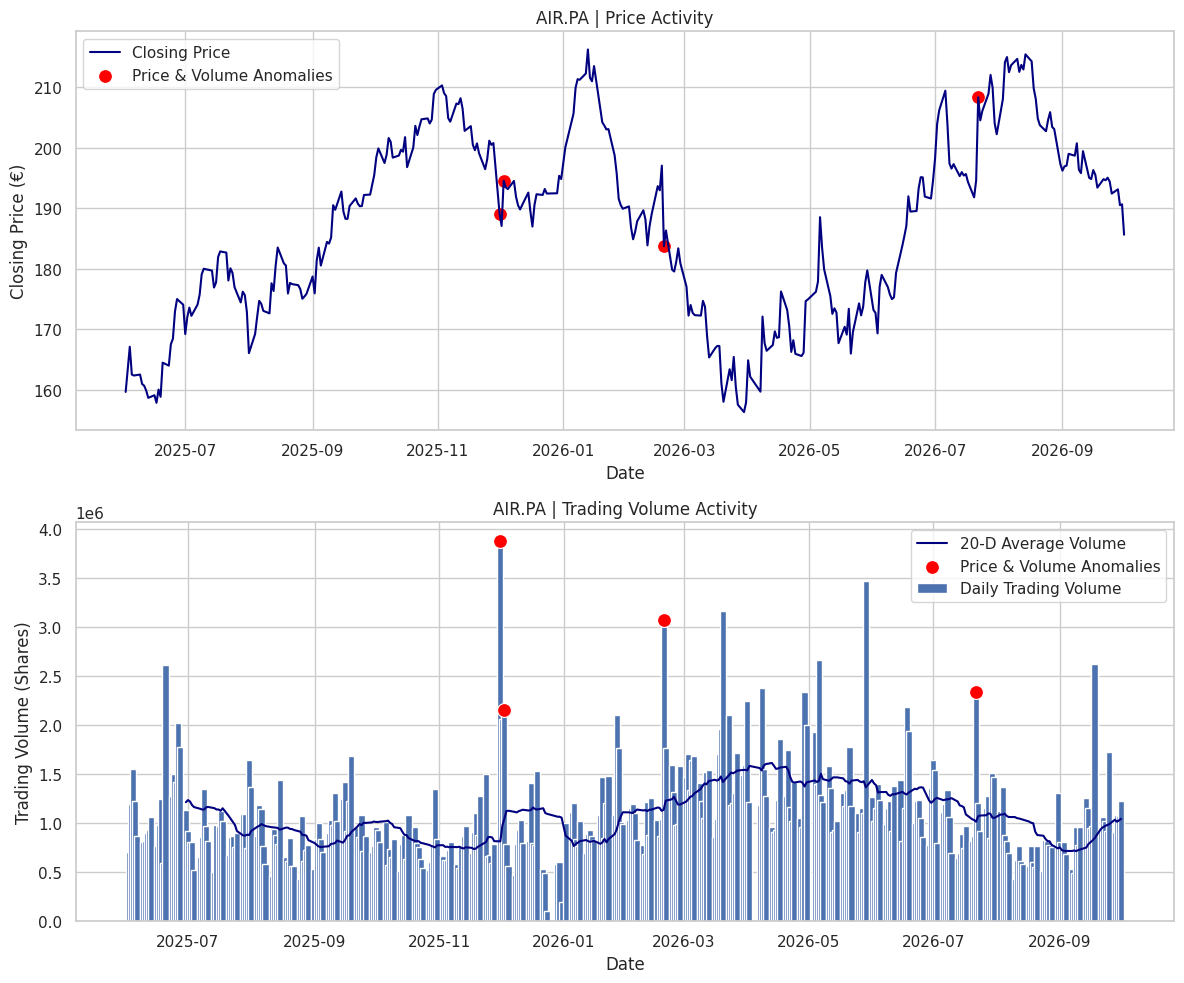

In [37]:
plot_market_anomalies('AIR.PA')

## 9 - Case Study

LVMH : January 28, 2026

### 9.1 - Alert Detection

In [38]:
(anomalies
 .loc[[('MC.PA', '2026-01-28')], :]
 .droplevel('Ticker')
 .reset_index()
 .rename_axis(columns=None)
 .style
 .hide(axis='index')
 .format('{:,.2f}')
 .format({'Date':'{:%Y-%m-%d}'}))

Date,Close,Volume,Daily Return,Average Volume 20D,Volume Ratio
2026-01-28,534.091064,1402549,-7.890714,377924.550000,3.711188


### 9.2 - Market Context

On January 27, 2026, LVMH reported its fourth-quarter and full-year 2025 financial results. The following trading session was marked by a sharp decline in its share price, as investors reacted to weakening profitability and cautious management guidance.

Several factors contributed to the negative market sentiment:

- Profitability pressure: The group’s annual operating margin declined from 23.1% in 2024 to 22.0% in 2025.
- Weakness in key divisions: Organic revenue in Fashion & Leather Goods fell by 3%, while Wines & Spirits sales declined by 9%.
- Slower-than-expected Asian recovery: Revenue in Asia excluding Japan increased by only 1% in Q4, raising concerns about the strength of the luxury sector’s recovery.
- Uncertain outlook: Management highlighted geopolitical tensions and economic uncertainty as risks for 2026.

Reuters reported that LVMH shares were down 6.82% during the January 28 trading session, with weakness extending to other European luxury companies.

Source: *'LVMH chute, déception sur la marge et la prudence affichée pour 2026 (actualisé)', Reuters, published in Les Échos, January 28, 2026 — article discussing LVMH’s Q4 results and the subsequent market reaction.*

### 9.3 - Financial Interpretation

The sharp decline in LVMH’s share price on January 28, 2026, can plausibly be linked to investors reassessing the company’s financial outlook following its earnings announcement.

Lower operating margins, weaker-than-expected performance in key business segments and cautious management guidance may have led some investors to revise their expectations of future profitability and reduce their exposure to the stock.

At the same time, other market participants may have viewed the price decline as an attractive entry opportunity, particularly given LVMH’s established position in the luxury industry.

This reassessment of expectations can help explain the combination of a −7.89% daily adjusted return and trading volume 3.71 times the previous 20-session average.

The elevated volume suggests unusually intense trading activity, while the negative return indicates significant downward price pressure.

Overall, the timing of the anomaly and the reported market reaction are consistent with an earnings-driven repricing of LVMH shares. However, the available daily data cannot establish individual investors’ motivations or prove that the earnings announcement was the sole cause of the movement.

### 9.4 - Surveillance Perspective

Although LVMH’s earnings announcement provides a plausible explanation for the January 28 anomaly, further surveillance checks could help assess whether any unusual trading activity occurred before the information became public.

A potential investigation could focus on:

* Pre-announcement activity: Examining trading volumes and price movements over the weeks or months preceding the earnings release, particularly after potentially price-sensitive information may have become available to certain individuals.
* Unusual trading patterns: Identifying significant transactions, abnormal selling activity or elevated trading volumes without corresponding price movements.
* Potential insider dealing: Where legally accessible, reviewing whether participants involved in unusual transactions had access to material non-public information before the announcement.

Importantly, unusual trading activity does not, by itself, constitute evidence of market abuse.

Model limitation: The current detector uses daily aggregated price and volume data. It can flag unusual trading sessions but cannot identify individual participants, establish access to confidential information or detect insider dealing.

Conclusion: The January 28 anomaly is consistent with an earnings-driven market reaction. However, pre-announcement trading activity could be examined separately to identify additional signals warranting investigation.

## 10 - Limitations & Next Steps

1. Statistical Anomalies vs. Market Manipulation

    This model identifies unusual price movements and trading volumes relative to historical statistical benchmarks. However, these anomalies do not necessarily indicate market manipulation. They may result from earnings announcements, macroeconomic developments, geopolitical events, or company-specific news.

2. Historical data requirements

    The detection methodology requires sufficient historical observations to calculate rolling statistics. Price anomaly detection relies on a 60-day historical window, while volume analysis uses a 20-day moving window average. The current trading day is excluded from the calculation of its price thresholds to prevent look-ahead bias.

3. Detection limitations

    This model focuses on significant price movements and unusually high trading volumes. As combined alerts require both conditions to be satisfied, smaller or less visible irregularities may remain undetected. Consequently, the absence of an alert does not guarantee the absence of suspicious market activity.

4. Parameter sensitivity

    Detection results depend on the selected rolling windows and statistical thresholds. Shorter windows may respond more quickly to market changes but produce less stable estimates, while longer windows may provide greater stability at the expense of responsiveness. Further sensitivity testing would be necessary to evaluate the robustness of these parameters.

5. Pre-announcement Trading Activity

    Future improvements could include the analysis of unusual trading activity preceding corporate announcements, such as earnings releases. Elevated trading volumes without significant price movements may also warrant further examination. However, investigating potential insider dealing would require more granular transaction data and information about market participants that are not available in the current dataset.